# Random Forest


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn import datasets

In [ ]:
iris = datasets.load_iris()

In [ ]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
data = pd.DataFrame({"sepal_length":iris.data[:,0],
                     "sepal_width":iris.data[:,1],
                     "petal_length":iris.data[:,2],
                     "petal_width":iris.data[:,3],
                     "output":iris.target})

In [ ]:
data

,sepal_length,sepal_width,petal_length,petal_width,output
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
#Split the dataset in train-test split

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
#Features and Output Splitting

In [ ]:
X=data[['sepal_length','sepal_width','petal_length','petal_width']]
y=data['output']

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.20)   #if we keep random_state = 42, we will get 100% accuracy.

In [ ]:
#Model Define
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model=RandomForestClassifier(n_estimators=100)   #n_estimators is the paraameter that defined the number of trees we want, and ultimately will be making 100 subsets of the dataset.

In [ ]:
model.fit(X_train,Y_train)

RandomForestClassifier()

In [ ]:
from sklearn.metrics import accuracy_score
y_pred=model.predict(X_test)
#Classification_score
print(accuracy_score(Y_test,y_pred))


0.9666666666666667


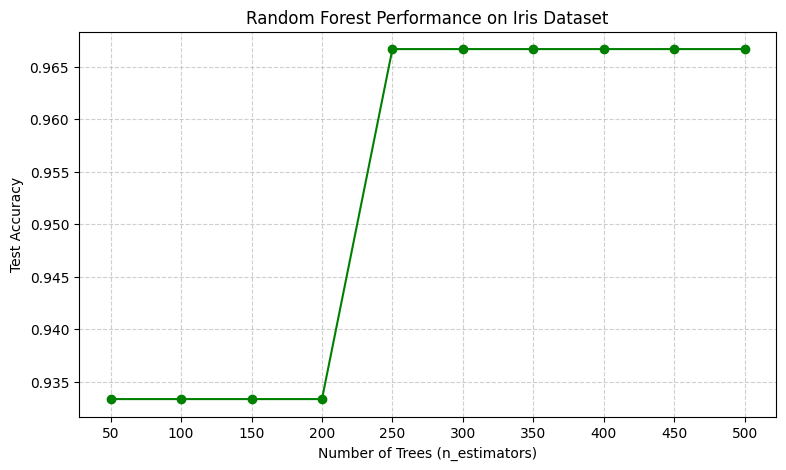

In [ ]:
tree_range = range(50, 501,50)
accuracies = []

#Train models and record accuracy scores
for n in tree_range:
  rf = RandomForestClassifier(n_estimators=n, random_state=42)
  rf.fit(X_train, Y_train)
  score = rf.score(X_test, Y_test)
  accuracies.append(score)

plt.figure(figsize=(9, 5))
plt.plot(tree_range, accuracies, marker="o", color="green", linestyle="-")
plt.title("Random Forest Performance on Iris Dataset")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Test Accuracy")
plt.xticks(tree_range)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


In [ ]:
#Visualization of the trees
from sklearn.tree import export_graphviz
import pydot

In [ ]:
tree=model.estimators_[10]
export_graphviz(tree,out_file="/content/tree.dot",feature_names=iris.feature_names)

In [ ]:
(graph,)=pydot.graph_from_dot_file("/content/tree.dot")

In [ ]:
graph.write("/content/tree.jpg")

True